In [1]:
!which python


/mnt/pixstor/data/lsxgf/miniconda/envs/py-scverse/bin/python


In [2]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
import numpy as np
import pandas as pd

In [3]:
up_de_target_genes_ = 'FGFBP2, GNLY, GZMB, HLA-DRA, IL7R, IRF4, LAIR2, TNFRSF18, XCL2, ZNF683, CD83, FASLG, GZMA'.split(', ')
down_de_target_genes_ = 'CCL20, DNAJB1, FOS, FTL, HMOX1, HSPB1, LEF1, LGALS1, DUSP1, HSPA1A, HSPA1B, ANXA1, CD69, DDIT3, CCR7, KLRG1, TIMP1'.split(', ')

from pathlib import Path
#save_dir = Path('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/model_explainability/Model_expl_20260117')

# 0816:
ensemble_mode = 'rankMin_study'
level = 'clonotype' # clonotype, cell

out_dir_root = Path("/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/model_explainability/Model_expl_20260814")
save_dir = out_dir_root / f'{ensemble_mode}_{level}'

gene_1_fiPath = save_dir / "GRN_gene_embedding_Chiffelle_genes_celltype_1.csv"
geneSet1 = pd.read_csv(gene_1_fiPath)
up_de_target_genes_ = geneSet1.iloc[:, 0].tolist()

gene_0_fiPath = save_dir / "GRN_gene_embedding_Chiffelle_genes_celltype_0.csv"
geneSet0 = pd.read_csv(gene_0_fiPath)
down_de_target_genes_ = geneSet0.iloc[:, 0].tolist()

In [4]:
down_de_target_genes_

['LGALS1',
 'HSPA1A',
 'HMOX1',
 'HSPA1B',
 'STMN1',
 'LEF1',
 'SAT1',
 'KLRG1',
 'HSPB1',
 'MYC',
 'ANXA1',
 'FOS',
 'DUSP1',
 'CD69',
 'TIMP1',
 'TUBA1B',
 'TUBB',
 'DNAJB1',
 'FTL',
 'MAL',
 'CCR7']

In [5]:
up_de_target_genes_

['GZMB',
 'CCL4',
 'CCL3',
 'KLRD1',
 'GNLY',
 'CD83',
 'KLRC1',
 'ZNF683',
 'TRDC',
 'XCL2',
 'GZMA',
 'IFNG',
 'GZMH',
 'CCL4L2',
 'FASLG',
 'DUSP2',
 'GADD45B',
 'TNFRSF18',
 'FGFBP2',
 'HLA-DRA',
 'TIGIT',
 'RGS1',
 'TNF',
 'TRGV5',
 'IRF4',
 'TRDV1']

In [7]:
len(down_de_target_genes_) + len(up_de_target_genes_) 

47

In [8]:
set(down_de_target_genes_) & set(up_de_target_genes_)

set()

In [6]:
Caushi = pd.read_csv("/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/caushi_nature_neoantigen_specificTIL/MANA_vs_Viral_gene_list.csv",
                     header = None)[0].tolist()
hanada_list_path = '/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/hanada_NSCLC_CancerCell/hanada_CD8_transcriptome_signature_fromPaperFigure6.csv'
Hanada = pd.read_csv(hanada_list_path, header=None)[0].tolist()
Hanada_pos = [x[:-1] for x in Hanada if x.endswith('+')]
Hanada_neg = [x[:-1] for x in Hanada if x.endswith('_')]

# read Meng TR30
Meng = pd.read_csv("/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/meng_scienceTranslationalMedicine_PDAC/meng_TR_30.csv",
                 header = None)[0].tolist()

Oliveira = pd.read_csv("/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/oliveira_melanoma_Nature/Oliveira_tumorVSviral_UpgeneList.csv",
                     header = None)[0].tolist()

Lowery = pd.read_csv('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/lowery_neoTCR_metastatic/Lowery_NeoTCR8.csv',
                     header = None)[0].tolist()

zheng_list_path = '/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/zheng_GI_cancer_CancerCell/93cvs2z3mz-2/Zheng_ExRevsNexNre_geneList_fromTable_S5.csv'

# Convert the DataFrame to a list of genes
Zheng = pd.read_csv(zheng_list_path, header=None)[0].tolist()

# Example 7 other gene lists (replace with your actual data)
other_gene_lists = [
    set(Caushi), set(Hanada_pos+Hanada_neg), set(Lowery),set(Meng),set(Oliveira), set(Zheng)
]

# Gene list names
gene_list_names = ["Caushi", "Hanada","Lowery", "Meng",  "Oliveira", "Zheng"]

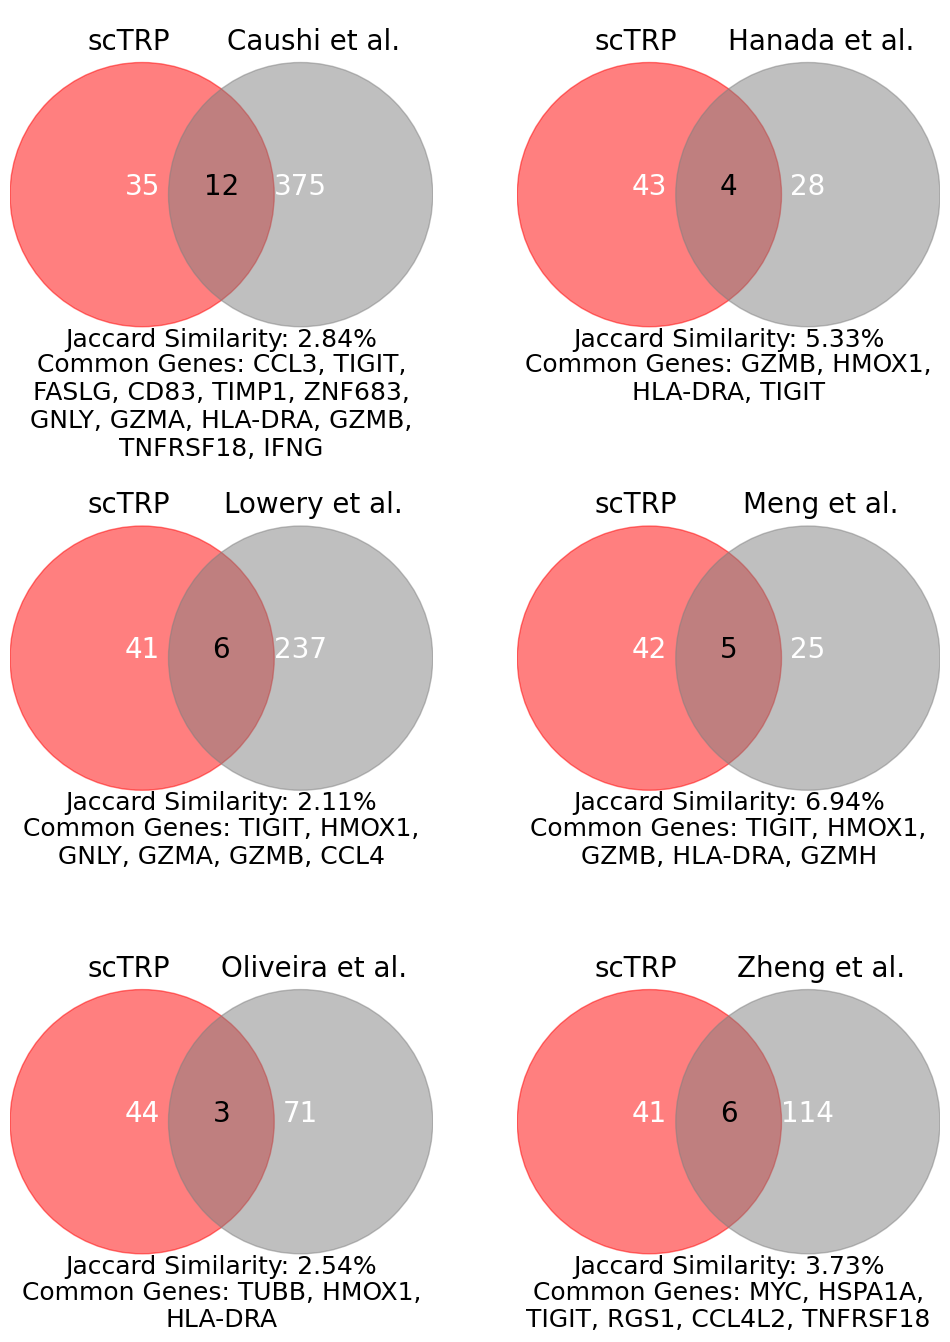

In [7]:
tem_list = list(set(up_de_target_genes_ + down_de_target_genes_))
from matplotlib.patches import Circle
import textwrap

def jaccard_similarity(set1, set2):
    intersection = len(set1 & set2)
    union = len(set1 | set2)
    return (intersection / union) * 100 if union != 0 else 0

n_plots = len(other_gene_lists)
ncols, nrows = 2, 3
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 6 * nrows))
axes = axes.flatten()

for i, (gene_list, name) in enumerate(zip(other_gene_lists, gene_list_names)):
    ax = axes[i]

    circle1 = Circle((-0.6, 0), 1, color='red', alpha=0.5)
    circle2 = Circle((0.6, 0), 1, color='grey', alpha=0.5)
    ax.add_patch(circle1)
    ax.add_patch(circle2)

    jaccard_sim = jaccard_similarity(set(tem_list), gene_list)
    ax.text(0, -1.15, f'Jaccard Similarity: {jaccard_sim:.2f}%', ha='center', fontsize=18)

    common_genes = list(set(tem_list) & gene_list)
    common_genes_str = 'Common Genes: '+ ", ".join(common_genes)
    wrapped = textwrap.fill(common_genes_str, width=32, break_long_words=False,
                            break_on_hyphens=False)
    ax.text(0, -1.2, f'{wrapped}', ha='center',  va='top', fontsize=18)

    intersection = len(set(tem_list) & gene_list)
    only_up = len(set(tem_list)) - intersection
    only_gene_list = len(gene_list) - intersection
    ax.text(-0.6, 0, f'{only_up}', ha='center', fontsize=20, color='white')
    ax.text(0.6, 0, f'{only_gene_list}', ha='center', fontsize=20, color='white')
    ax.text(0, 0, f'{intersection}', ha='center', fontsize=20, color='black')

    ax.text(-0.7, 1.1, 'scTRP', ha='center', fontsize=20)
    ax.text(0.7, 1.1, f'{name} et al.', ha='center', fontsize=20)

    ax.set_aspect('equal', 'box')
    ax.set_xlim(-1.6, 1.6)
    ax.set_ylim(-1.4, 1.4)
    ax.axis('off')
    #ax.set_title(f'scTRP Genes vs. {name}')

# Hide any unused subplot slots (e.g. if you have 5 gene lists but a 2x3=6 grid)
for j in range(n_plots, len(axes)):
    axes[j].axis('off')

#plt.tight_layout()
plt.subplots_adjust(wspace=0.20, hspace=0.01)  # wspace = horizontal gap between columns

plot_filename = save_dir / 'scTRP_geneEmbGenesVs_all.svg'
plt.savefig(plot_filename, format='svg', dpi=300)
plt.show()

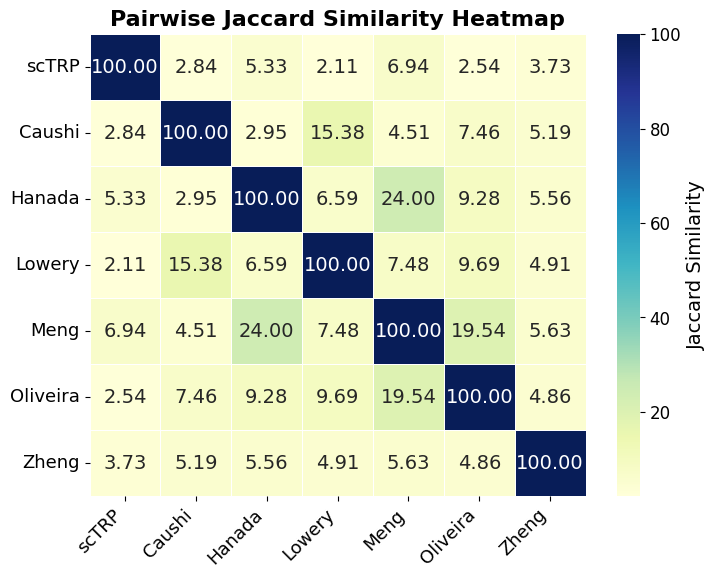

In [8]:
set(up_de_target_genes_+down_de_target_genes_)

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



gene_lists = [
   set(up_de_target_genes_+down_de_target_genes_), set(Caushi), set(Hanada_pos+Hanada_neg), set(Lowery),set(Meng),set(Oliveira), set(Zheng)
]

# Gene list names
gene_list_names = ['scTRP',"Caushi", "Hanada","Lowery", "Meng",  "Oliveira", "Zheng"]


# Function to compute Jaccard similarity
def jaccard_similarity(set1, set2):
    intersection = len(set1 & set2)
    union = len(set1 | set2)
    return (intersection / union) * 100 if union != 0 else 0  # Return as percentage

# Initialize a matrix to store pairwise Jaccard similarity
jaccard_matrix = np.zeros((len(gene_lists), len(gene_lists)))

# Compute pairwise Jaccard similarity
for i in range(len(gene_lists)):
    for j in range(i, len(gene_lists)):  # Only compute for half of the matrix since it's symmetric
        similarity = jaccard_similarity(gene_lists[i], gene_lists[j])
        jaccard_matrix[i, j] = similarity
        jaccard_matrix[j, i] = similarity  # Fill the symmetric part

# Convert the matrix to a DataFrame for better visualization
jaccard_df = pd.DataFrame(jaccard_matrix, index=gene_list_names, columns=gene_list_names)

# Plotting the heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(jaccard_df, annot=True, cmap='YlGnBu', fmt=".2f", linewidths=.5,
                  cbar_kws={'label': 'Jaccard Similarity'},
                  annot_kws={"size": 14, }) # , "weight": "bold"})

# Title
plt.title("Pairwise Jaccard Similarity Heatmap", fontsize=16, fontweight="bold")

# Axis tick labels (row/column names)
ax.set_xticklabels(ax.get_xticklabels(), fontsize=13, rotation=45, ha="right") # fontweight="bold", 
ax.set_yticklabels(ax.get_yticklabels(), fontsize=13,  rotation=0) # fontweight="bold",

# Colorbar label and ticks
cbar = ax.collections[0].colorbar
cbar.set_label('Jaccard Similarity', fontsize=14)
cbar.ax.tick_params(labelsize=12)

plot_filename = save_dir / f'scTRP_geneEmbGenes_pairwiseJaccard.svg'
plt.savefig(plot_filename, format='svg', dpi=300, bbox_inches="tight")
plt.show()